In [7]:
import os

import numpy as np
import pandas as pd


import PIL 
import cv2
import matplotlib.pyplot as plt
%matplotlib inline

from PIL import ImageOps,Image
from IPython.display import display
from skimage.filters import frangi

In [8]:
data_dir = 'C:/Users/pray1/Documents/MNet_DeepCDR/mnet_deep_cdr/test_img'

In [23]:
img_size = 512
def img_to_array(img):
    img = np.array(img.getdata()).reshape(img.width, img.width, 3) / 255
    img = (img*255).astype('uint8')
    return img


def trim(im):
    """trim black margin, 
    http://stackoverflow.com/questions/10615901/trim-whitespace-using-pil"""
    bg = PIL.Image.new(im.mode, im.size, im.getpixel((0,0)))
    diff = PIL.ImageChops.difference(im, bg)
    diff = PIL.ImageChops.add(diff, diff, 2.0, -20)
    bbox = diff.getbbox()
    if bbox:
        return im.crop(bbox)


def calc_thumbnail_size(img):
    """calculate thumbnail size with constant aspect ratio"""
    width, length = img.size
    ratio = width / length

    # for some reason, if it's exactly 224, then thumnailed image is 223
    dim = img_size + 1          # output dim
    if ratio > 1:
        size = (dim * ratio, dim)
    else:
        size = (dim, dim / ratio)
    return size


def calc_crop_coords(img):
    """crop to square of desired dimension size"""
    dim = img_size
    width, length = img.size
    left = 0
    right = width
    bottom = length
    top = 0
    if width > dim:
        delta = (width - dim) / 2
        left = delta
        right = width - delta
    if length > dim:
        delta = (length - dim) / 2
        top = delta
        bottom = length - delta
    return (left, top, right, bottom)


def preprocess(img,border=0):
    img = trim(img)
    tsize = calc_thumbnail_size(img)
    img.thumbnail(tsize)
    crop_coords = calc_crop_coords(img)
    img = img.crop(crop_coords)
    return img

In [10]:
def clahe_hsv(img, cliplimit=None, tilesize=8):
    """
    Apply CLAHE to the V channel of an HSV image.
    """
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    hsv_planes = list(cv2.split(hsv))
    clahe = cv2.createCLAHE(clipLimit=cliplimit, tileGridSize=(tilesize, tilesize))
    hsv_planes[2] = clahe.apply(hsv_planes[2])
    hsv = cv2.merge(hsv_planes)
    bgr = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
    return bgr

def is_dark(image_path, threshold=90):
    """
    Checks if an image is dark enough to apply a Laplacian filter.
    
    Args:
        image: input image in numpy array format
        threshold: the threshold for average pixel value to consider the image dark, default is 100
        
    Returns:
        True if image is considered dark, False otherwise
    """
    image = cv2.imread(image_path)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    average_pixel_value = np.mean(gray)
    
    if average_pixel_value < threshold:
        return True
    else:
        return False


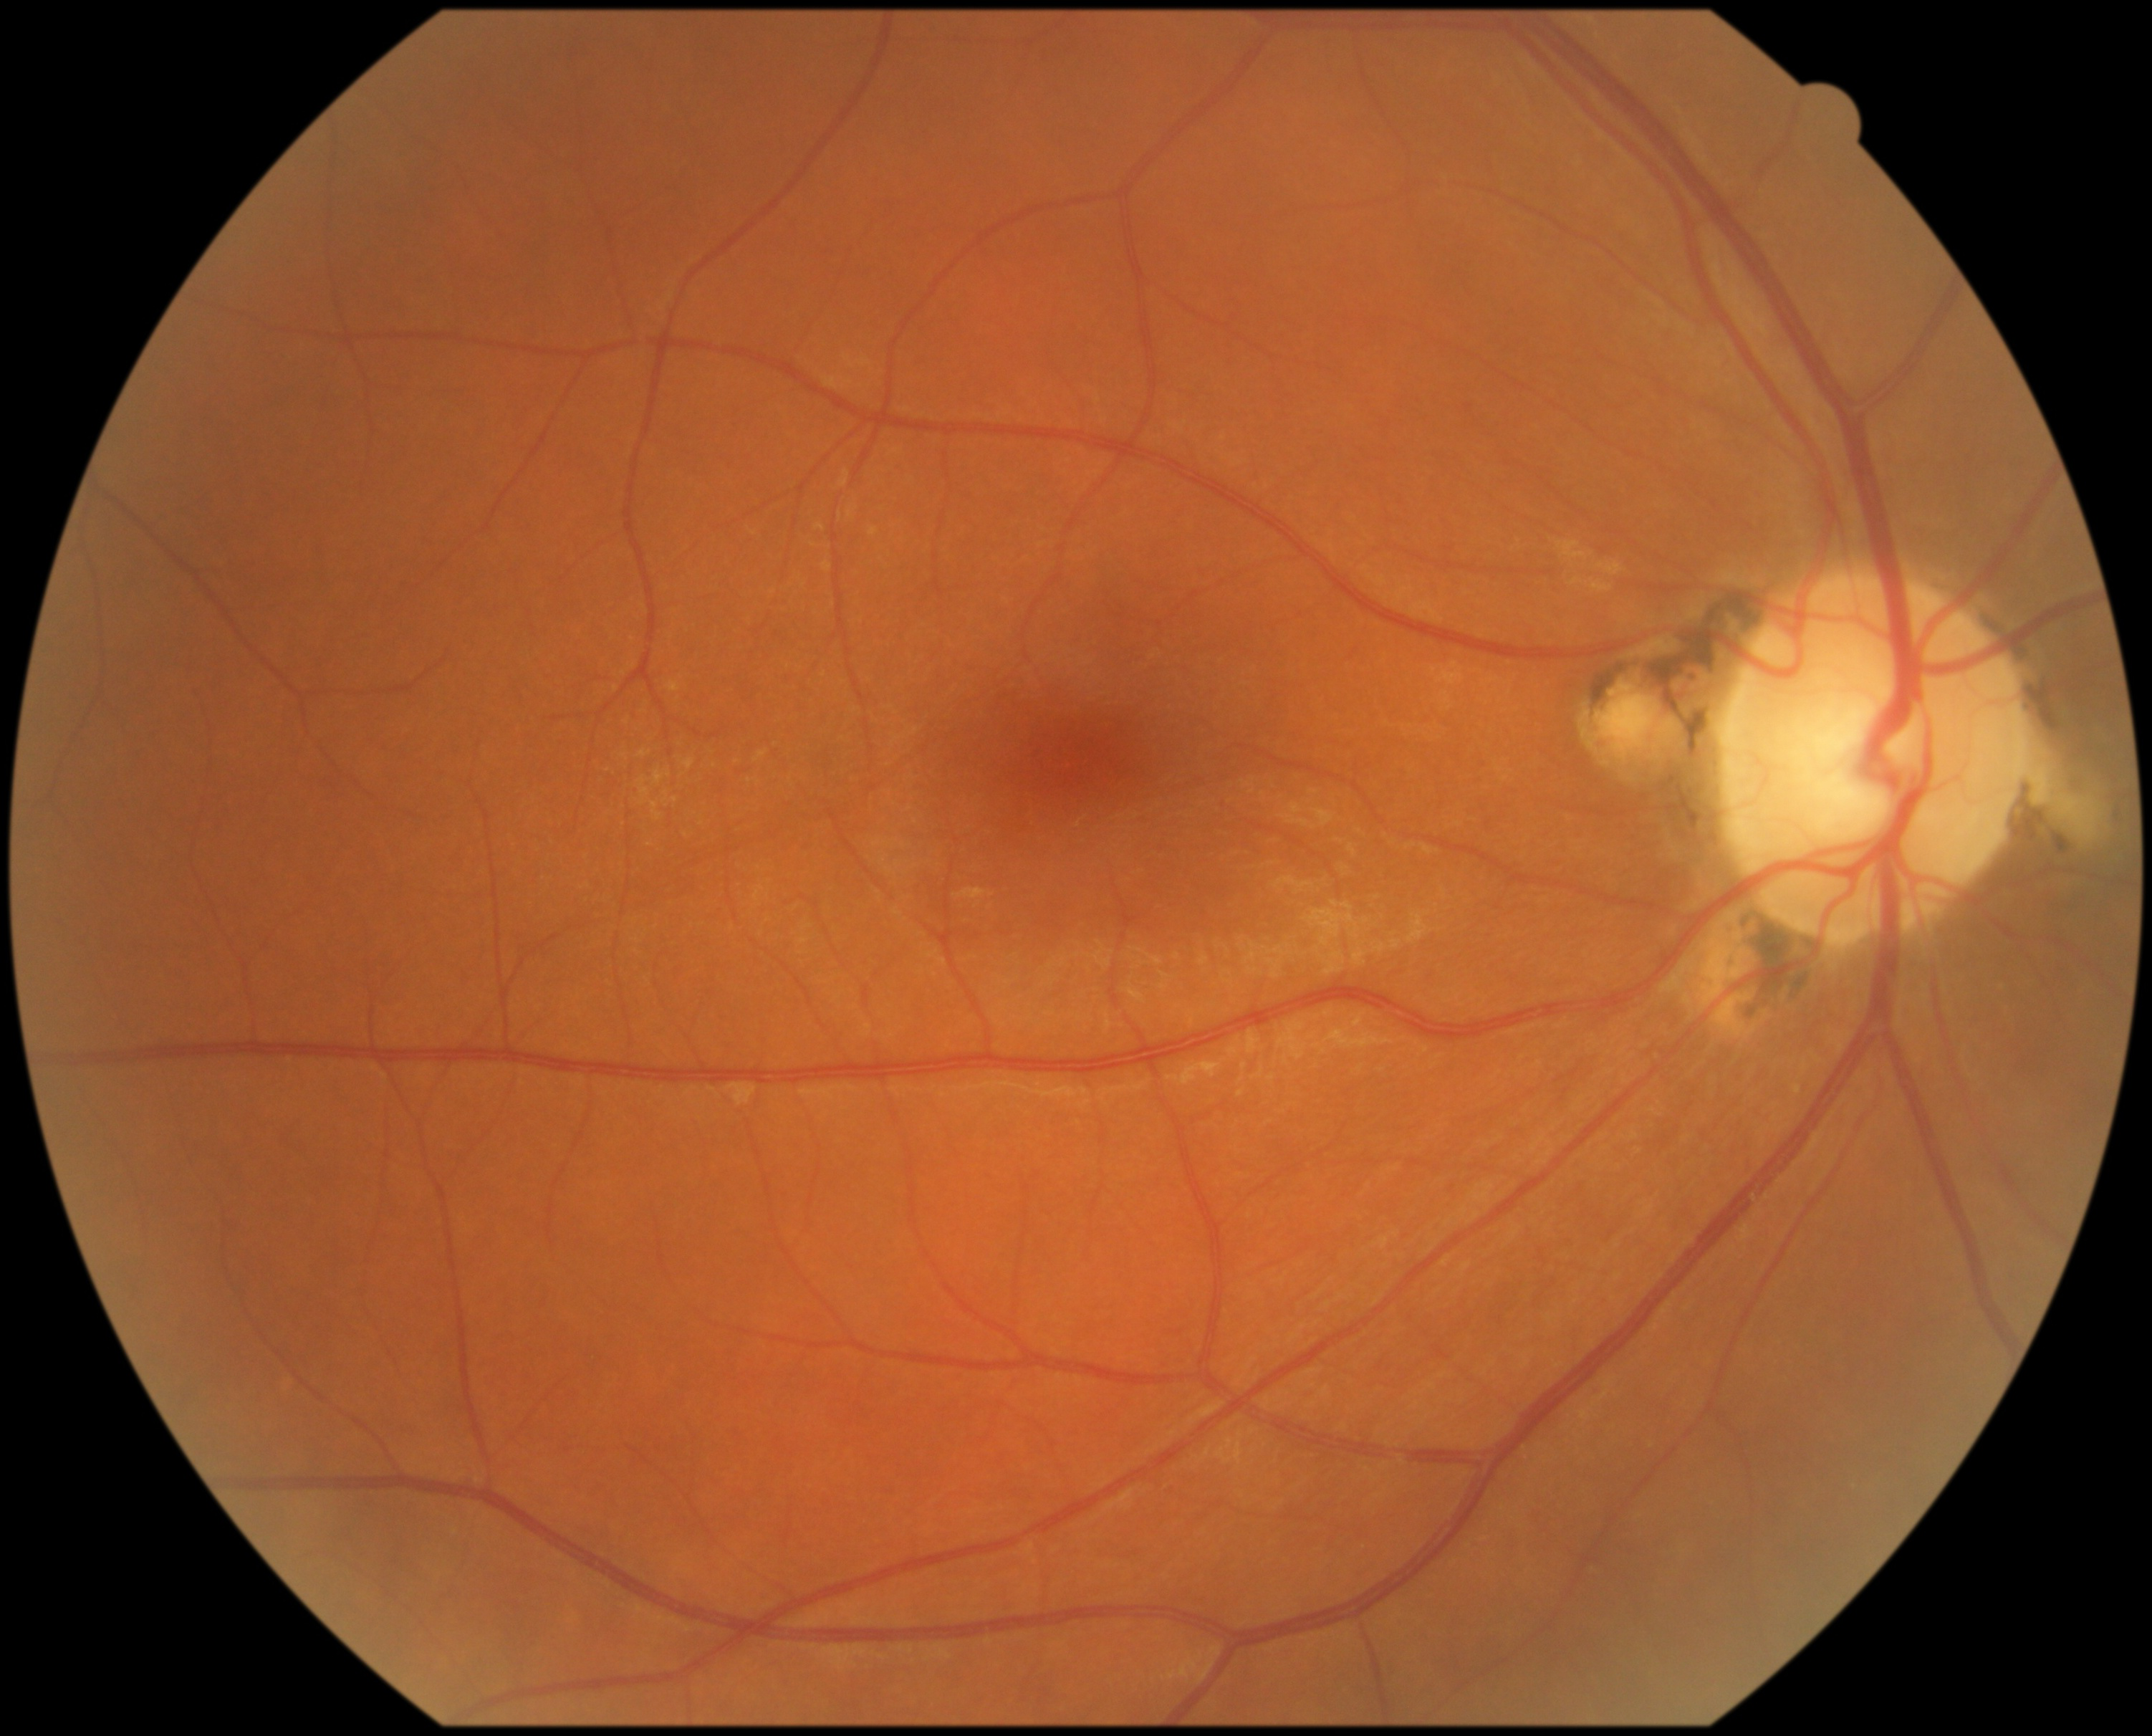

In [25]:
img_path = data_dir+'/image_2232.jpg'
im = Image.open(img_path)
#im = preprocess(im)
input_img = cv2.imread(img_path)
#im = img_to_array(im)
display(im)

In [12]:
im = Image.open(img_path)
im = preprocess(im)
im = np.array(im)
im = cv2.cvtColor(im, cv2.COLOR_RGB2BGR)
"""
if is_dark(img_path):
    gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    # Apply the Laplacian filter to the grayscale image
    laplacian = cv2.Laplacian(gray, cv2.CV_8U)
    # Add the Laplacian result to the original color image
    im = cv2.addWeighted(im, 1.5, cv2.cvtColor(laplacian, cv2.COLOR_GRAY2BGR), -0.5, 0)
"""
#------------------------------------------------#
bgr = clahe_rgb(im, cliplimit=4.0, tilesize=32)
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(cv2.cvtColor(input_img, cv2.COLOR_BGR2RGB))
axes[0].set_title('Original')
axes[1].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
axes[1].set_title('CLAHE + Vessel Removal')

FileNotFoundError: [Errno 2] No such file or directory: 'C:/Users/pray1/Documents/MNet_DeepCDR/mnet_deep_cdr/test_img/n0078.jpg'

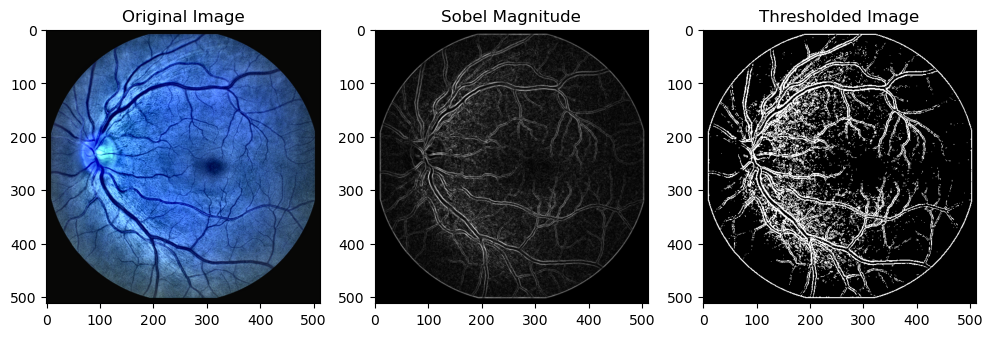

In [11]:
# Convert the image to grayscale
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

# Apply Sobel filter for edge detection
sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

# Convert the output of Sobel filter to binary image using thresholding
sobel_mag = np.sqrt(sobelx**2 + sobely**2)
sobel_mag = np.uint8(sobel_mag/np.max(sobel_mag)*255)
thresh_value, thresh = cv2.threshold(sobel_mag, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Display the output
fig, axes = plt.subplots(1, 3, figsize=(12, 6))
axes[0].imshow(bgr)
axes[0].set_title('Original Image')
axes[1].imshow(sobel_mag, cmap='gray')
axes[1].set_title('Sobel Magnitude')
axes[2].imshow(thresh, cmap='gray')
axes[2].set_title('Thresholded Image')
plt.show()


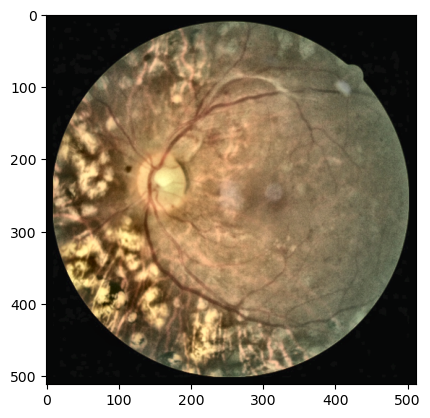

In [8]:
bgr = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
pil_img = Image.fromarray(bgr)

# Save the image as PNG
pil_img.save('F:/archive\eyepacs_preprocess\preprocessed_data\\1159_left.png')

# Display the image
plt.imshow(pil_img)
plt.show()

In [3]:
def preprocessing(img_path):
    im = Image.open(img_path)
    im = preprocess(im)
    im = np.array(im)
    im = cv2.cvtColor(im, cv2.COLOR_RGB2BGR)
    if is_dark(img_path):
        gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
        # Apply the Laplacian filter to the grayscale image
        laplacian = cv2.Laplacian(gray, cv2.CV_8U)
        # Add the Laplacian result to the original color image
        im = cv2.addWeighted(im, 1.5, cv2.cvtColor(laplacian, cv2.COLOR_GRAY2BGR), -0.5, 0)
    bgr = clahe_rgb(im, cliplimit=4.0, tilesize=16)
    return bgr

In [10]:
"""
input_dir = data_dir
output_dir = 'F:/archive\eyepacs_preprocess\preprocessed_data'
preprocessed_img = preprocessing(img_path)
preprocessed_img = cv2.cvtColor(preprocessed_img, cv2.COLOR_BGR2RGB)
pil_img = Image.fromarray(preprocessed_img)
output_path = os.path.join(output_dir, 'jedi2.png')
pil_img.save(output_path)
"""

"\ninput_dir = data_dir\noutput_dir = 'F:/archive\\eyepacs_preprocess\\preprocessed_data'\npreprocessed_img = preprocessing(img_path)\npreprocessed_img = cv2.cvtColor(preprocessed_img, cv2.COLOR_BGR2RGB)\npil_img = Image.fromarray(preprocessed_img)\noutput_path = os.path.join(output_dir, 'jedi2.png')\npil_img.save(output_path)\n"

In [12]:
from tqdm import tqdm
# Set input and output directories
input_dir = data_dir
output_dir = 'F:/archive\eyepacs_preprocess\preprocessed_data'

num_files = len(os.listdir(input_dir))

# Initialize the progress bar
progress_bar = tqdm(total=num_files, desc='loading', colour='green')

# Iterate through each image file in the input directory
for filename in os.listdir(input_dir):
    progress_bar.update(1)
    # Load the image
    img_path = os.path.join(input_dir, filename)
    # Preprocess the image
    preprocessed_img = preprocessing(img_path)
    preprocessed_img = cv2.cvtColor(preprocessed_img, cv2.COLOR_BGR2RGB)
    # Save the preprocessed image to the output directory
    pil_img = Image.fromarray(preprocessed_img)
    output_path = os.path.join(output_dir, filename)
    pil_img.save(output_path)
    
progress_bar.close()

loading: 100%|██████████| 35108/35108 [1:44:01<00:00,  5.62it/s]    


In [11]:
img_path = 'C:/Users/pray1/Documents/MNet_DeepCDR/mnet_deep_cdr/test_img/CS50041_R.jpg'
output_dir = 'C:/Users/pray1/Documents/MNet_DeepCDR/mnet_deep_cdr/test_img'
preprocessed_img = preprocessing(img_path)
preprocessed_img = cv2.cvtColor(preprocessed_img, cv2.COLOR_BGR2RGB)
pil_img = Image.fromarray(preprocessed_img)
output_path = os.path.join(output_dir, 'CS50041_R_pre.jpg')
pil_img.save(output_path)